In [33]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.quantum_info import SparsePauliOp

import numpy as np
from numpy import pi, sqrt

from itertools import product

from matplotlib import pyplot as plt

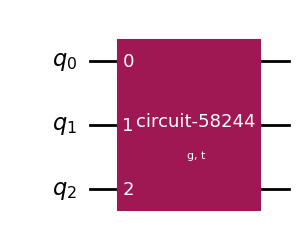

In [182]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * (t / N)
theta_B = 1 / (g**2 * np.sqrt(2)) * t / N

def one_step(n):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(-theta_E, q)

    for i in range(1, n - 1):
        # Flip controls from |0⟩ to |1⟩
        qc.x(i - 1)
        qc.x(i + 1)

        controlled_u = UGate(theta_B, -pi/2, pi/2).control(1)

        qc.append(controlled_u, [i, i + 1])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])

        # Flip back controls
        qc.x(i - 1)
        qc.x(i + 1)

    return qc

def N_steps_repeat(n, N):
    one_step_circuit = one_step(n)
    full_circuit = one_step_circuit.repeat(N)
    return full_circuit

n = 3
N = 1
full_circuit = N_steps_repeat(n, N)
full_circuit.draw("mpl")

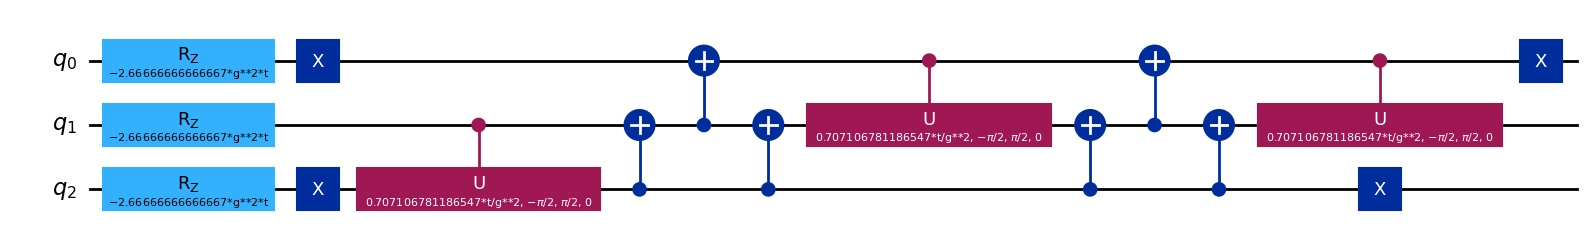

In [183]:
def N_steps_compose(n, N):
    one_step_circuit = one_step(n)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
full_circuit = N_steps_compose(n, N)
full_circuit.draw("mpl")

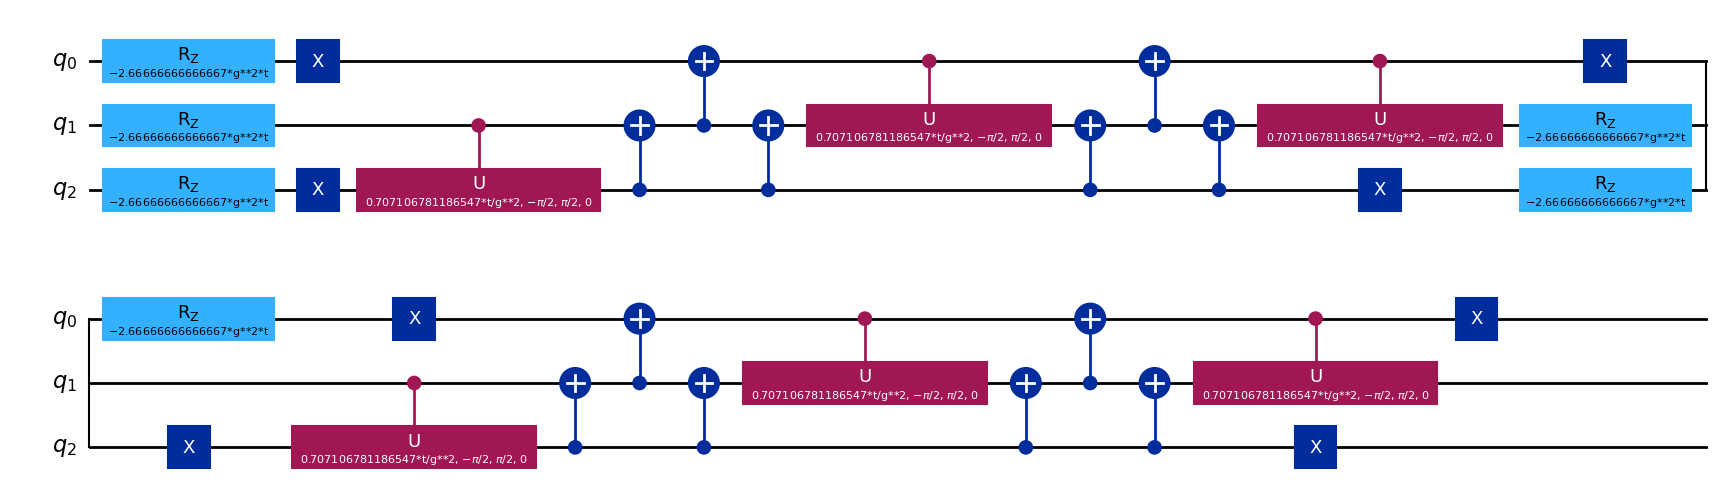

In [184]:
n = 3
N = 2
full_circuit = N_steps_compose(n, N)
full_circuit.draw("mpl")

<h1>Measurment</h1>

In [186]:
pauli_labels = [''.join(p) for p in product('IXYZ', repeat=3)]

# Create SparsePauliOp objects for each
observables = [SparsePauliOp(label) for label in pauli_labels]
observables_labels = pauli_labels

In [187]:
qc = N_steps_compose(3, 1)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

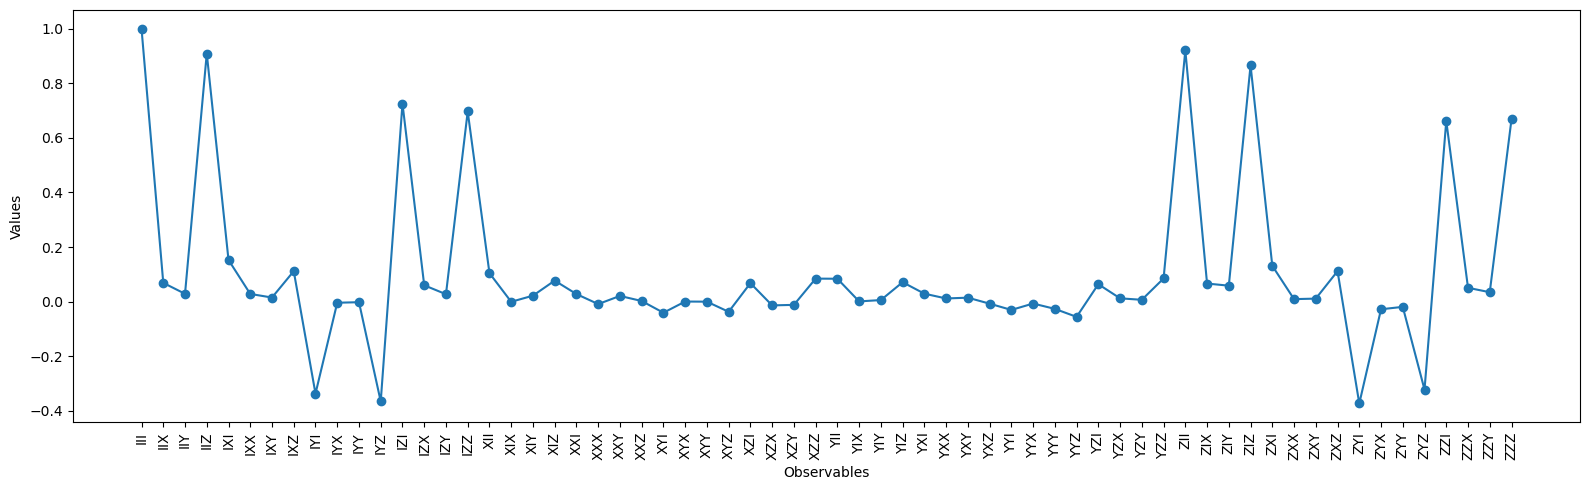

In [188]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.figure(figsize=(16, 5))

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

<h1>Measurement for N=2</h1>

In [190]:
qc = N_steps_compose(3, 2)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

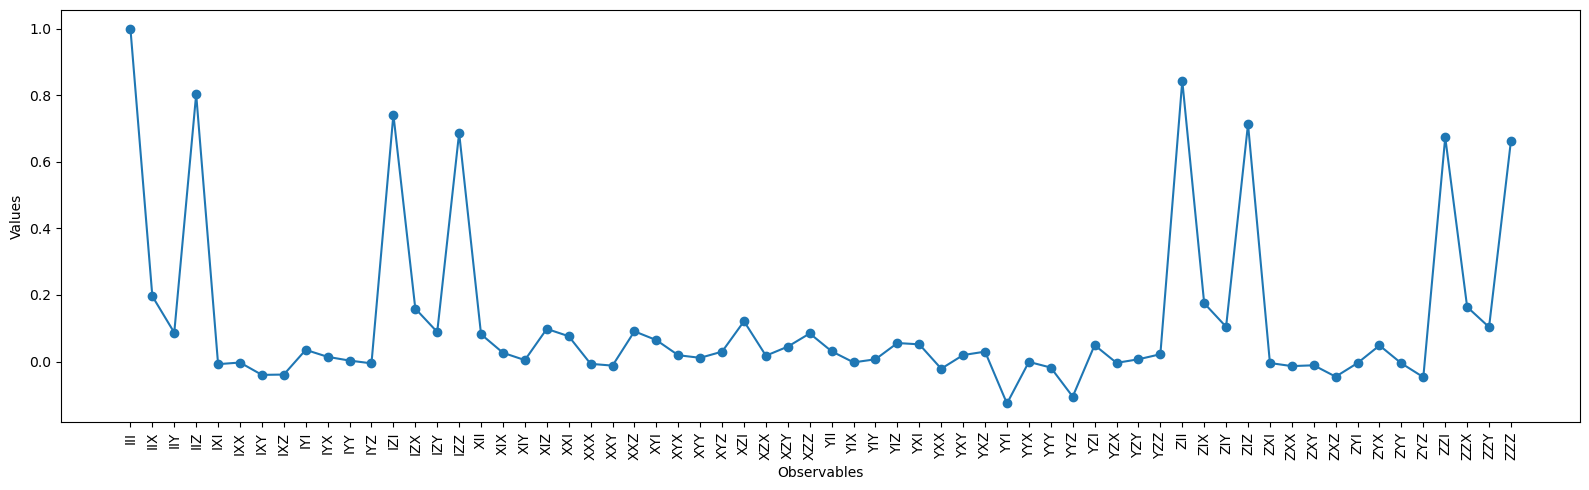

In [191]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.figure(figsize=(16, 5))

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

<h1>Measurement for N=100</h1>

In [193]:
qc = N_steps_compose(3, 100)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

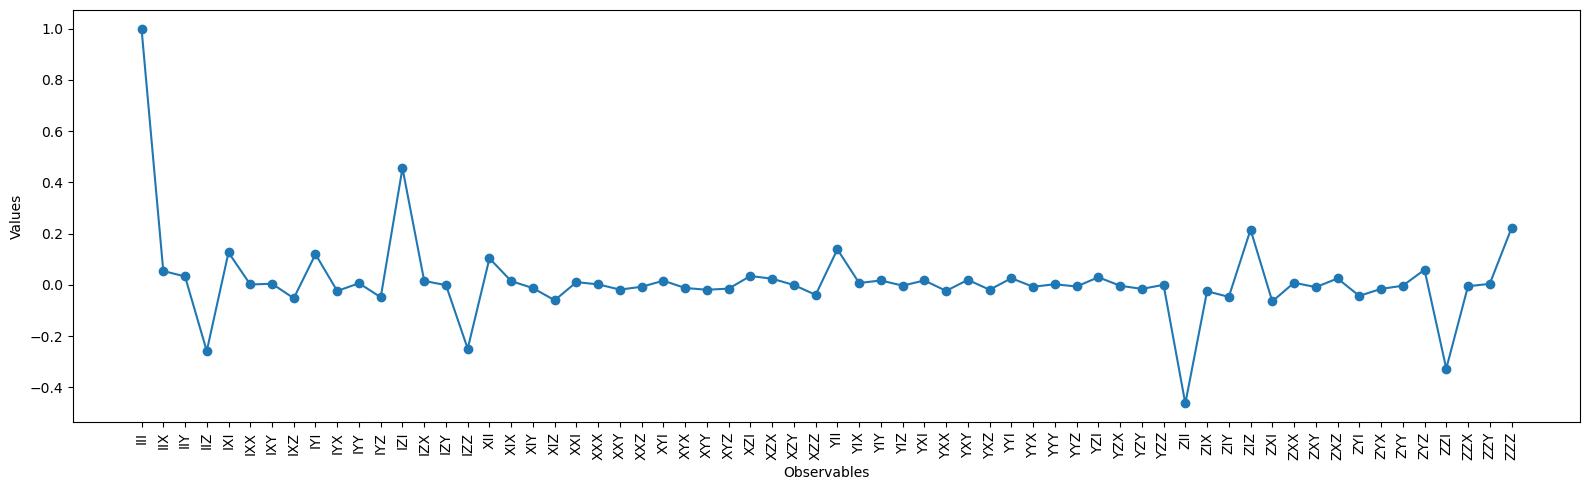

In [194]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.figure(figsize=(16, 5))

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

<h1>Z measurement on N=1</h1>

In [196]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

In [197]:
qc = N_steps_compose(3, 1)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

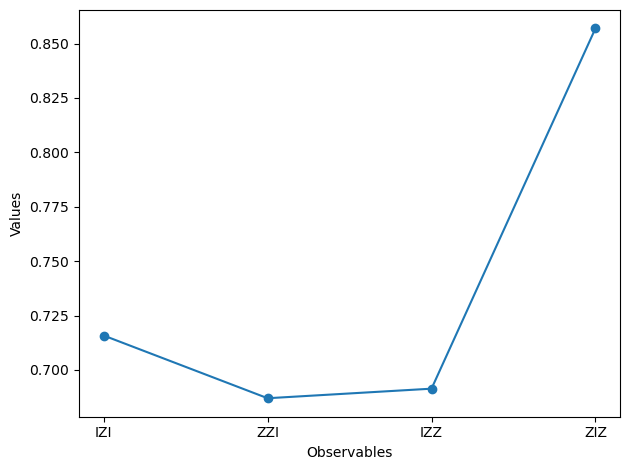

In [198]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

<h1>Z measurement on N=50</h1>

In [200]:
qc = N_steps_compose(3, 2)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

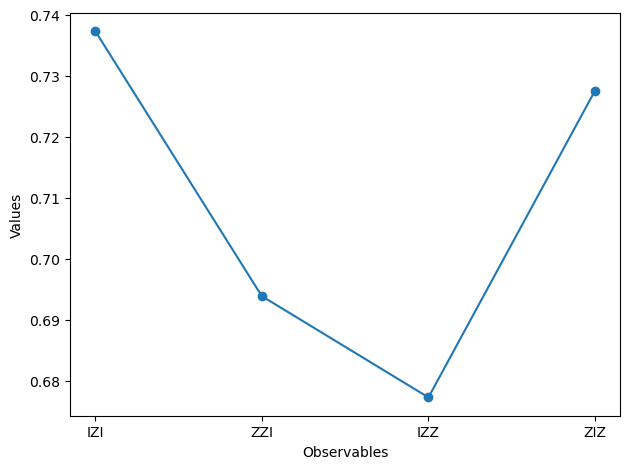

In [201]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.savefig('test0.png')
plt.show()

<h1>Z measurement on N=100</h1>

In [203]:
qc = N_steps_compose(3, 100)
qc = qc.assign_parameters({g:1., t:1.})

from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
backend = FakeAlmadenV2()
estimator = Estimator(backend)
 
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc)
mapped_observables = [
    observable.apply_layout(isa_circuit.layout) for observable in observables
]
 
job = estimator.run([(isa_circuit, mapped_observables)])
result = job.result()
 
job_result = job.result()
 
pub_result = job.result()[0]

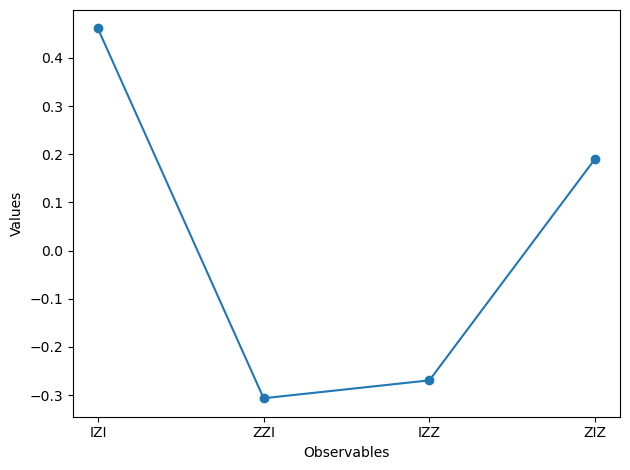

In [204]:
values = pub_result.data.evs
errors = pub_result.data.stds

plt.plot(observables_labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.savefig('test0.png')
plt.show()